In [2]:
import pandas as pd
import tkinter as tk
from tkinter import filedialog

# 1. Crea y oculta la ventana de fondo de Tkinter
root = tk.Tk()
root.withdraw()

# Hace que la ventana de selección aparezca por encima de otras aplicaciones
root.attributes('-topmost', True)

# 2. Abre el explorador para que elijas tu archivo CSV (como cuando eliges un Excel)
ruta = filedialog.askopenfilename(
    title="Selecciona tu archivo CSV",
    filetypes=[("Archivos CSV", "*.csv"), ("Todos los archivos", "*.*")]
)

# 3. Si seleccionaste un archivo, lo lee con Pandas y te muestra las primeras 10 filas
if ruta:
    df = pd.read_csv(ruta)
    print(df.head(10))
else:
    print("No seleccionaste ningún archivo.")


    # Ver información general: nombres de columnas, cantidad de datos no nulos y tipo de dato
print("\nInformación general:")
print(df.info())

# Ver el tipo de dato de cada columna por separado
print("\nTipos de datos por columna:")
print(df.dtypes)

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   
5  15.0          8         429.0       198.0    4341          10.0   
6  14.0          8         454.0       220.0    4354           9.0   
7  14.0          8         440.0       215.0    4312           8.5   
8  14.0          8         455.0       225.0    4425          10.0   
9  15.0          8         390.0       190.0    3850           8.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa         

#Carga `auto_mpg.csv` y realiza el primer contacto con el dataset. Reporta dimensiones, 
primeras filas, tipos de datos y define qué representa una fila.

In [5]:
#Pregunta 1 

print(df.shape)
print(df.head())
print(df.info())
print(df.dtypes)

(398, 9)
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   

In [6]:
# PREGUNTA 2
print(df.dtypes)

mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin              str
name                str
dtype: object


In [7]:
#PREGUNTA 3
print(df.isnull().sum())
proporcion_nulos = df.isnull().sum() / len(df) * 100
print(proporcion_nulos)
print("Duplicados exactos:", df.duplicated().sum())

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64
mpg             0.000000
cylinders       0.000000
displacement    0.000000
horsepower      1.507538
weight          0.000000
acceleration    0.000000
model_year      0.000000
origin          0.000000
name            0.000000
dtype: float64
Duplicados exactos: 0


In [8]:
#PREGUNTA 4
print("Nombres distintos:", df['name'].nunique())
print("Total de filas:", len(df))
repetidos = df['name'].value_counts()
print(repetidos.head(10))
ejemplo = df[df['name'] == repetidos.index[0]]
print(ejemplo[['name', 'model_year', 'weight']])

Nombres distintos: 305
Total de filas: 398
name
ford pinto            6
ford maverick         5
amc matador           5
toyota corolla        5
chevrolet impala      4
amc hornet            4
peugeot 504           4
amc gremlin           4
toyota corona         4
chevrolet chevette    4
Name: count, dtype: int64
           name  model_year  weight
32   ford pinto          71    2046
112  ford pinto          73    2310
130  ford pinto          74    2451
168  ford pinto          75    2639
174  ford pinto          75    2984
206  ford pinto          76    2565


In [9]:
#PREGUNTA 5
columnas = ['mpg', 'weight', 'horsepower']
for col in columnas:
    print(col)
    print("Media:", df[col].mean())
    print("Mediana:", df[col].median())
    print("Desv. estándar:", df[col].std())
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    print("Q1:", q1, "Q3:", q3, "IQR:", q3 - q1)
    print()

mpg
Media: 23.514572864321607
Mediana: 23.0
Desv. estándar: 7.815984312565782
Q1: 17.5 Q3: 29.0 IQR: 11.5

weight
Media: 2970.424623115578
Mediana: 2803.5
Desv. estándar: 846.8417741973268
Q1: 2223.75 Q3: 3608.0 IQR: 1384.25

horsepower
Media: 104.46938775510205
Mediana: 93.5
Desv. estándar: 38.49115993282849
Q1: 75.0 Q3: 126.0 IQR: 51.0



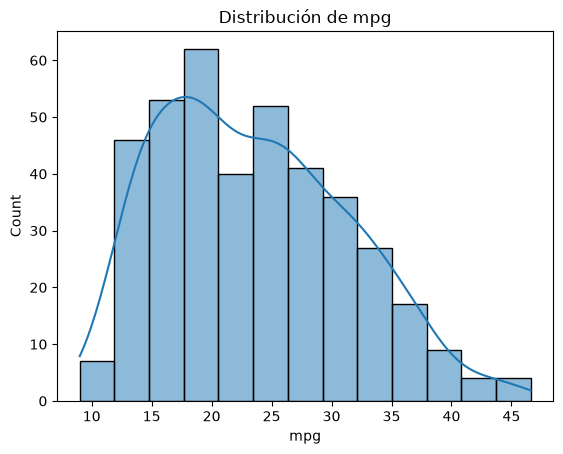

In [12]:
#PREGUNTA 6

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['mpg'], kde=True)
plt.title('Distribución de mpg')
plt.show()

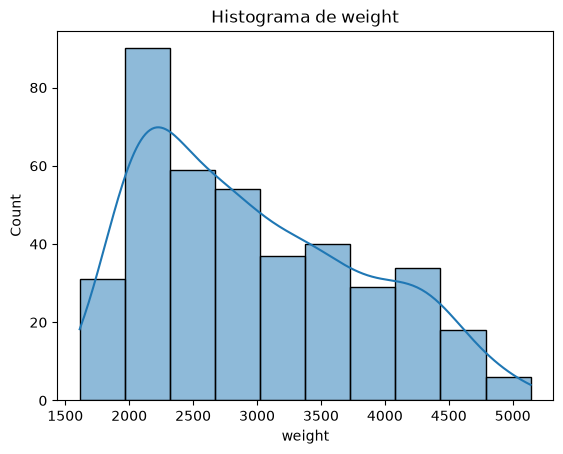

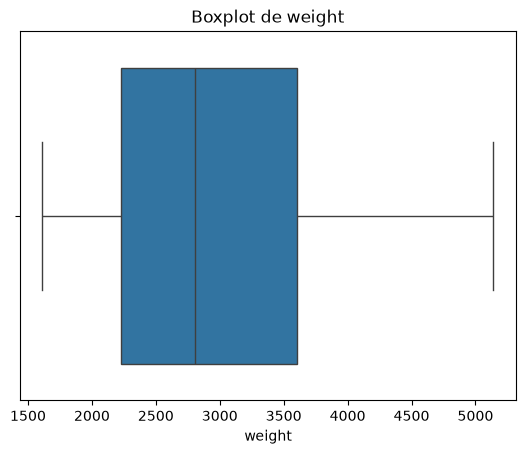

Límite inferior: 147.375
Límite superior: 5684.375
Empty DataFrame
Columns: [mpg, cylinders, displacement, horsepower, weight, acceleration, model_year, origin, name]
Index: []


In [13]:
#PREGUNTA 7 
sns.histplot(df['weight'], kde=True)
plt.title('Histograma de weight')
plt.show()

sns.boxplot(x=df['weight'])
plt.title('Boxplot de weight')
plt.show()

q1 = df['weight'].quantile(0.25)
q3 = df['weight'].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

outliers_weight = df[(df['weight'] < limite_inferior) | (df['weight'] > limite_superior)]
print(outliers_weight)

In [14]:
#PREGUNTA 8
q1 = df['horsepower'].quantile(0.25)
q3 = df['horsepower'].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_hp = df[(df['horsepower'] < limite_inferior) | (df['horsepower'] > limite_superior)]
print(outliers_hp[['name', 'horsepower']])

                             name  horsepower
6                chevrolet impala       220.0
7               plymouth fury iii       215.0
8                pontiac catalina       225.0
13        buick estate wagon (sw)       225.0
25                      ford f250       215.0
27                     dodge d200       210.0
67                mercury marquis       208.0
94   chrysler new yorker brougham       215.0
95       buick electra 225 custom       225.0
116            pontiac grand prix       230.0


cylinders
4    204
8    103
6     84
3      4
5      3
Name: count, dtype: int64
origin
usa       249
japan      79
europe     70
Name: count, dtype: int64


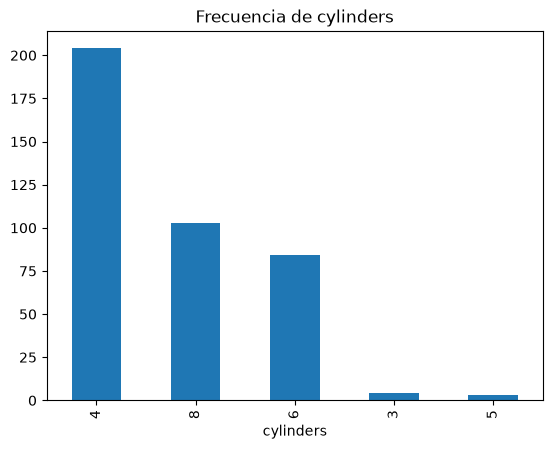

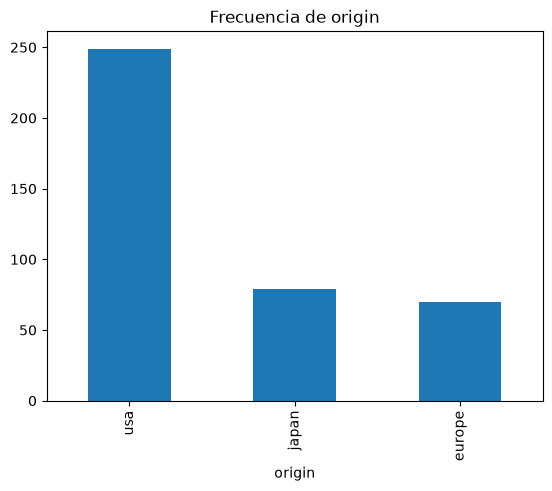

In [15]:
#PREGUNTA 9
print(df['cylinders'].value_counts())
print(df['origin'].value_counts())

df['cylinders'].value_counts().plot(kind='bar')
plt.title('Frecuencia de cylinders')
plt.show()

df['origin'].value_counts().plot(kind='bar')
plt.title('Frecuencia de origin')
plt.show()

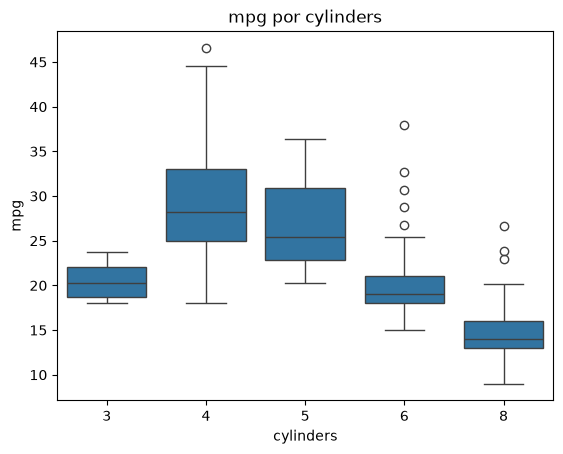

cylinders
3    20.550000
4    29.286765
5    27.366667
6    19.985714
8    14.963107
Name: mpg, dtype: float64
cylinders
3    20.25
4    28.25
5    25.40
6    19.00
8    14.00
Name: mpg, dtype: float64


In [16]:
#PREGUNTA 10
orden_cilindros = sorted(df['cylinders'].unique())

sns.boxplot(x='cylinders', y='mpg', data=df, order=orden_cilindros)
plt.title('mpg por cylinders')
plt.show()

print(df.groupby('cylinders')['mpg'].mean())
print(df.groupby('cylinders')['mpg'].median())

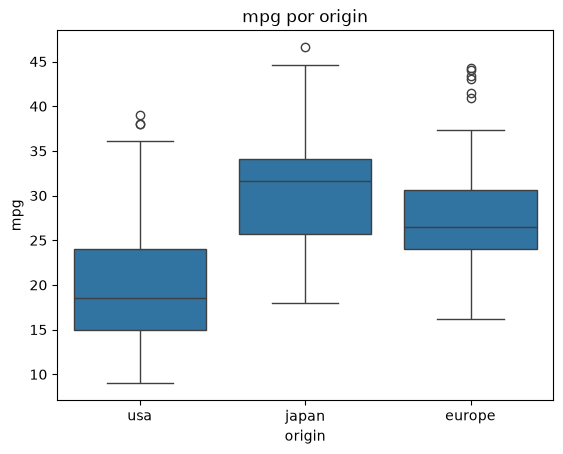

origin
europe    27.891429
japan     30.450633
usa       20.083534
Name: mpg, dtype: float64
origin
europe    26.5
japan     31.6
usa       18.5
Name: mpg, dtype: float64


In [17]:
#PREGUNTA 11
sns.boxplot(x='origin', y='mpg', data=df)
plt.title('mpg por origin')
plt.show()

print(df.groupby('origin')['mpg'].mean())
print(df.groupby('origin')['mpg'].median())

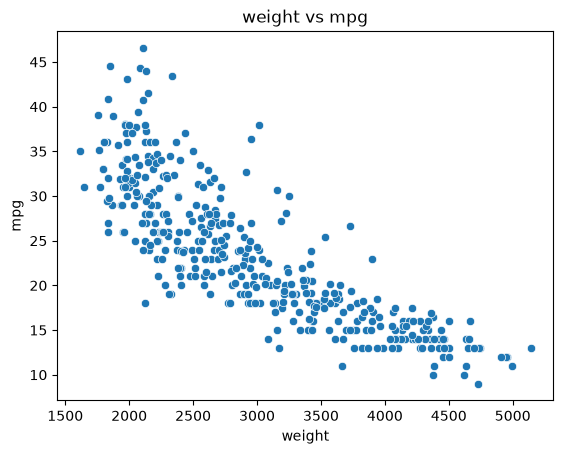

-0.8317409332443354


In [18]:
#PREGUNTA 12
sns.scatterplot(x='weight', y='mpg', data=df)
plt.title('weight vs mpg')
plt.show()

print(df['weight'].corr(df['mpg']))

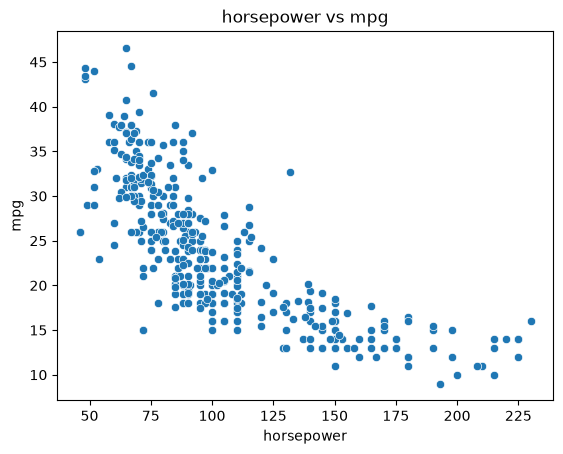

-0.7784267838977761


In [19]:
#PREGUNTA 13
df_sin_nulos = df.dropna(subset=['horsepower'])

sns.scatterplot(x='horsepower', y='mpg', data=df_sin_nulos)
plt.title('horsepower vs mpg')
plt.show()

print(df_sin_nulos['horsepower'].corr(df_sin_nulos['mpg']))

                   mpg  cylinders  displacement  horsepower    weight  \
mpg           1.000000  -0.775396     -0.804203   -0.778427 -0.831741   
cylinders    -0.775396   1.000000      0.950721    0.842983  0.896017   
displacement -0.804203   0.950721      1.000000    0.897257  0.932824   
horsepower   -0.778427   0.842983      0.897257    1.000000  0.864538   
weight       -0.831741   0.896017      0.932824    0.864538  1.000000   
acceleration  0.420289  -0.505419     -0.543684   -0.689196 -0.417457   
model_year    0.579267  -0.348746     -0.370164   -0.416361 -0.306564   

              acceleration  model_year  
mpg               0.420289    0.579267  
cylinders        -0.505419   -0.348746  
displacement     -0.543684   -0.370164  
horsepower       -0.689196   -0.416361  
weight           -0.417457   -0.306564  
acceleration      1.000000    0.288137  
model_year        0.288137    1.000000  


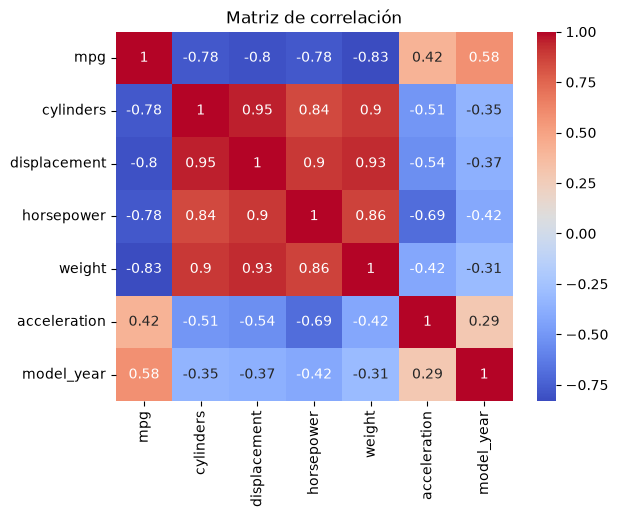

weight         -0.831741
displacement   -0.804203
horsepower     -0.778427
cylinders      -0.775396
acceleration    0.420289
model_year      0.579267
mpg             1.000000
Name: mpg, dtype: float64


In [20]:
#PREGUNTA 14

numericas = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']

matriz_corr = df[numericas].corr()
print(matriz_corr)

sns.heatmap(matriz_corr, annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

print(matriz_corr['mpg'].sort_values())

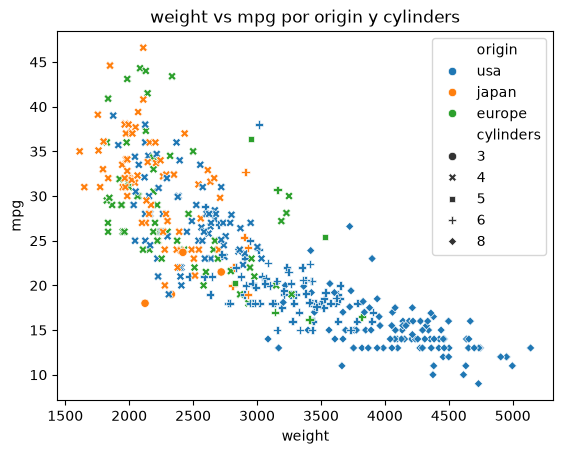

model_year
70    17.689655
71    21.250000
72    18.714286
73    17.100000
74    22.703704
75    20.266667
76    21.573529
77    23.375000
78    24.061111
79    25.093103
80    33.696552
81    30.334483
82    31.709677
Name: mpg, dtype: float64


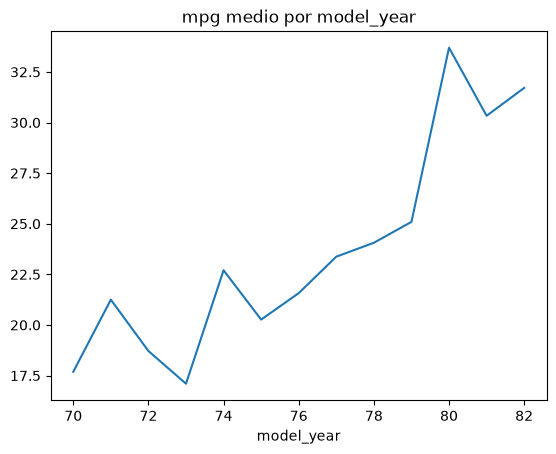

In [21]:
#PREGUNTA 15
sns.scatterplot(x='weight', y='mpg', hue='origin', style='cylinders', data=df)
plt.title('weight vs mpg por origin y cylinders')
plt.show()

print(df.groupby('model_year')['mpg'].mean())

df.groupby('model_year')['mpg'].mean().plot(kind='line')
plt.title('mpg medio por model_year')
plt.show()

model_year
70    17.689655
71    21.250000
72    18.714286
73    17.100000
74    22.703704
75    20.266667
76    21.573529
77    23.375000
78    24.061111
79    25.093103
80    33.696552
81    30.334483
82    31.709677
Name: mpg, dtype: float64
model_year
70    16.00
71    19.00
72    18.50
73    16.00
74    24.00
75    19.50
76    21.00
77    21.75
78    20.70
79    23.90
80    32.70
81    31.60
82    32.00
Name: mpg, dtype: float64


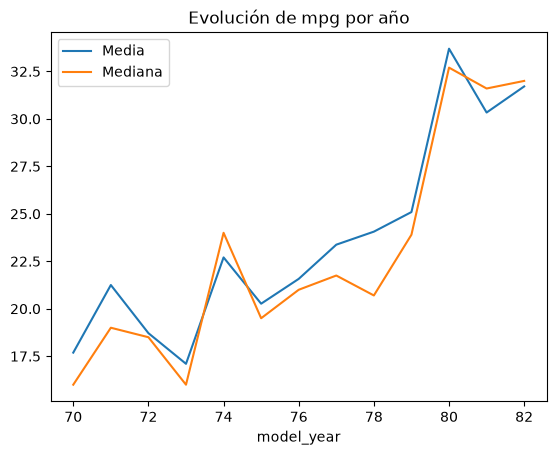

In [22]:
#PREGUNTA 16
media_por_anio = df.groupby('model_year')['mpg'].mean()
mediana_por_anio = df.groupby('model_year')['mpg'].median()

print(media_por_anio)
print(mediana_por_anio)

media_por_anio.plot(kind='line', label='Media')
mediana_por_anio.plot(kind='line', label='Mediana')
plt.legend()
plt.title('Evolución de mpg por año')
plt.show()

origin
europe    2423.300000
japan     2221.227848
usa       3361.931727
Name: weight, dtype: float64
origin
europe    2240.0
japan     2155.0
usa       3365.0
Name: weight, dtype: float64


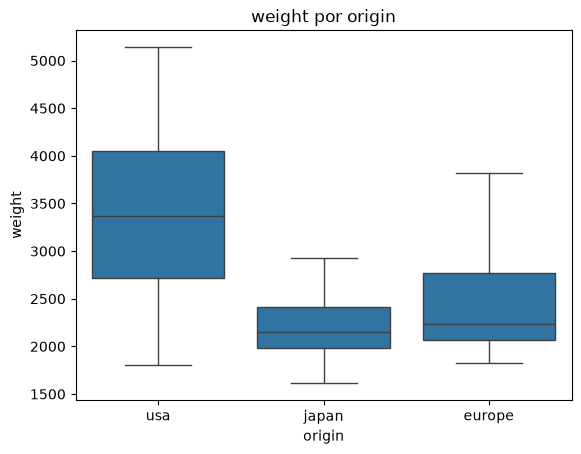

In [23]:
#PREGUNTA 17

print(df.groupby('origin')['weight'].mean())
print(df.groupby('origin')['weight'].median())

sns.boxplot(x='origin', y='weight', data=df)
plt.title('weight por origin')
plt.show()

In [24]:
#PREGUNTA 18
nulos_hp = df[df['horsepower'].isnull()]

print(nulos_hp['origin'].value_counts())
print(nulos_hp['cylinders'].value_counts())
print(nulos_hp['model_year'].value_counts())

origin
usa       4
europe    2
Name: count, dtype: int64
cylinders
4    5
6    1
Name: count, dtype: int64
model_year
80    2
71    1
74    1
81    1
82    1
Name: count, dtype: int64


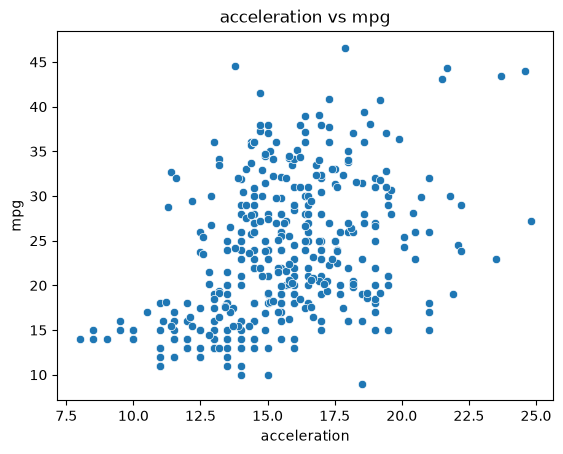

0.42028891210165065


In [25]:
#PREGUNTA 19
sns.scatterplot(x='acceleration', y='mpg', data=df)
plt.title('acceleration vs mpg')
plt.show()

print(df['acceleration'].corr(df['mpg']))

              displacement  horsepower    weight
displacement      1.000000    0.897257  0.932994
horsepower        0.897257    1.000000  0.864538
weight            0.932994    0.864538  1.000000


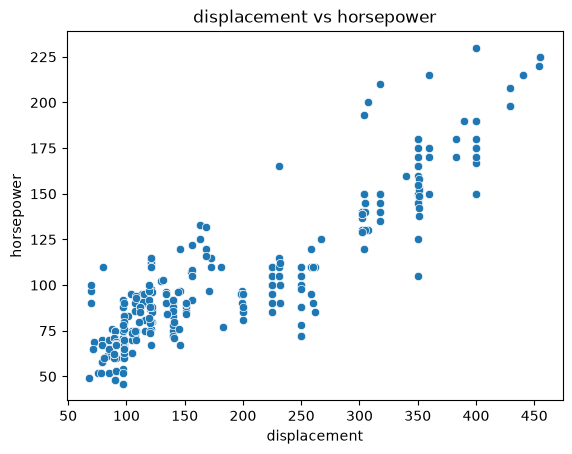

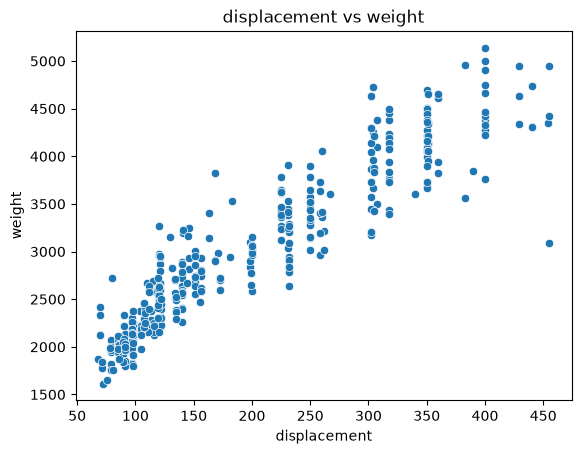

In [26]:
#PREGUNTA 20
df_sin_nulos = df.dropna(subset=['horsepower'])

print(df_sin_nulos[['displacement', 'horsepower', 'weight']].corr())

sns.scatterplot(x='displacement', y='horsepower', data=df_sin_nulos)
plt.title('displacement vs horsepower')
plt.show()

sns.scatterplot(x='displacement', y='weight', data=df_sin_nulos)
plt.title('displacement vs weight')
plt.show()

In [27]:
#PREGUNTA 21
tabla_pivote = df.pivot_table(values='mpg', index='cylinders', columns='origin', aggfunc='mean')
print(tabla_pivote)

conteo = df.pivot_table(values='mpg', index='cylinders', columns='origin', aggfunc='count')
print(conteo)

origin        europe      japan        usa
cylinders                                 
3                NaN  20.550000        NaN
4          28.411111  31.595652  27.840278
5          27.366667        NaN        NaN
6          20.100000  23.883333  19.663514
8                NaN        NaN  14.963107
origin     europe  japan    usa
cylinders                      
3             NaN    4.0    NaN
4            63.0   69.0   72.0
5             3.0    NaN    NaN
6             4.0    6.0   74.0
8             NaN    NaN  103.0


origin         europe      japan        usa
model_year                                 
70          25.200000  25.500000  15.272727
71          28.750000  29.500000  18.100000
72          22.000000  24.200000  16.277778
73          24.000000  20.000000  15.034483
74          27.000000  29.333333  18.333333
75          24.500000  27.500000  17.550000
76          24.250000  28.000000  19.431818
77          29.250000  27.416667  20.722222
78          24.950000  29.687500  21.772727
79          30.450000  32.950000  23.478261
80          37.288889  35.400000  25.914286
81          31.575000  32.958333  27.530769
82          40.000000  34.888889  29.450000


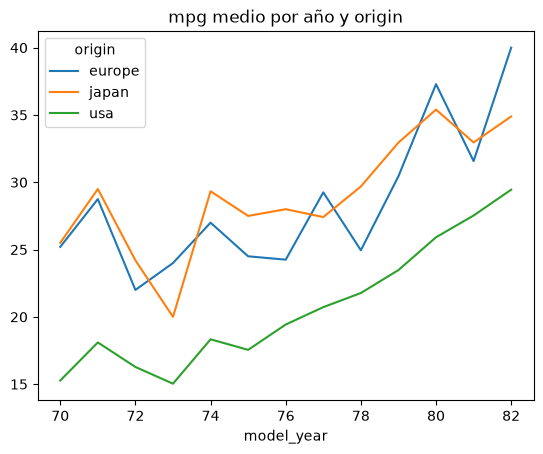

In [28]:
#PREGUNTA 22
tabla_tiempo = df.groupby(['model_year', 'origin'])['mpg'].mean().unstack()
print(tabla_tiempo)

tabla_tiempo.plot(kind='line')
plt.title('mpg medio por año y origin')
plt.show()

In [29]:
#PREGUNTA 23

df_sin_nulos = df.dropna(subset=['horsepower']).copy()

q1 = df_sin_nulos['horsepower'].quantile(0.25)
q3 = df_sin_nulos['horsepower'].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
outliers_iqr = df_sin_nulos[(df_sin_nulos['horsepower'] < limite_inferior) | (df_sin_nulos['horsepower'] > limite_superior)]

media = df_sin_nulos['horsepower'].mean()
desv = df_sin_nulos['horsepower'].std()
df_sin_nulos['z_score'] = (df_sin_nulos['horsepower'] - media) / desv
outliers_z = df_sin_nulos[df_sin_nulos['z_score'].abs() > 3]

print("Outliers por IQR:")
print(outliers_iqr[['name', 'horsepower']])

print("Outliers por z-score:")
print(outliers_z[['name', 'horsepower']])

Outliers por IQR:
                             name  horsepower
6                chevrolet impala       220.0
7               plymouth fury iii       215.0
8                pontiac catalina       225.0
13        buick estate wagon (sw)       225.0
25                      ford f250       215.0
27                     dodge d200       210.0
67                mercury marquis       208.0
94   chrysler new yorker brougham       215.0
95       buick electra 225 custom       225.0
116            pontiac grand prix       230.0
Outliers por z-score:
                         name  horsepower
6            chevrolet impala       220.0
8            pontiac catalina       225.0
13    buick estate wagon (sw)       225.0
95   buick electra 225 custom       225.0
116        pontiac grand prix       230.0


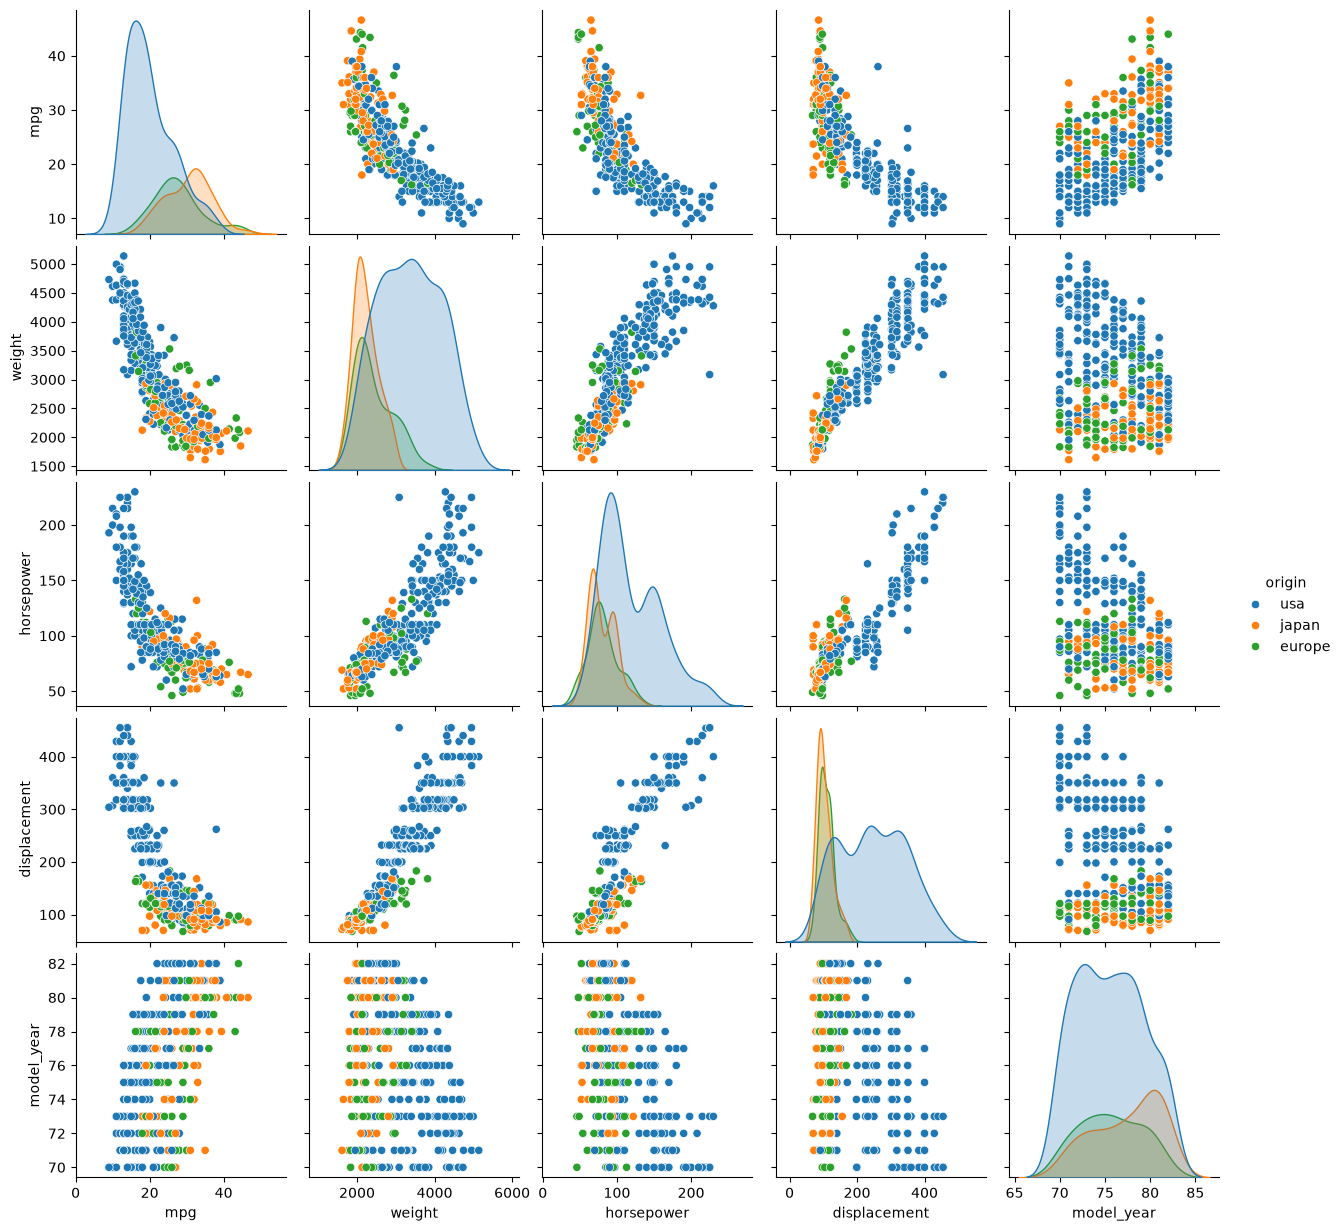

In [30]:
#PREGUNTA 24
columnas_pair = ['mpg', 'weight', 'horsepower', 'displacement', 'model_year', 'origin']
sns.pairplot(df[columnas_pair].dropna(), hue='origin')
plt.show()

#PREGUNTA 25
En base al EDA decidiria que los nulos de horsepower no los alteraria, usando dropna solo cuando haga falta calcular algo puntual. Ya para el modelo sí tocaría decidir entre imputar con la mediana o directamente elimino esas filas, dependiendo de cuántos nulos tengan.

Los outliers de potencia los mantendría documentados pero sin tocarlos en esta etapa, porque me servirian para entender el dataset. Si al final voy a entrenar un modelo, ahí evalúo caso por caso si son autos deportivos reales los dejo, si parecen un error de captura los corrijo o los saco.

Y con displacement, horsepower y weight, que están bastante correlacionadas entre sí, para el análisis exploratorio las tres aportan porque ayudan a entender el fenómeno. Pero si las meto todas juntas en un modelo predictivo, me arriesgo a multicolinealidad, así que ahí me quedaría con una o dos nada más.